Colin Klick

October 13, 2026

The following code reproduces the results used in my Cat Coat Phenotypes presentation, located in this Github repository.

In [68]:
!pip install -r /work/pi_elinor_broadinstitute_org/users/colin/pheno/requirements_fixed.txt

Defaulting to user installation because normal site-packages is not writeable


In [69]:
import sys
import importlib
sys.path.append("/work/pi_elinor_broadinstitute_org/users/colin/pheno/")

In [70]:
import pheno
import pheno.phenodb
importlib.reload(pheno.phenodb)
from pheno.phenodb import PhenoDB

db_cat = PhenoDB("/scratch4/workspace/bryc_broadinstitute_org-darwins_cats/phenotype/2026-08-28", "cat")

INFO:pheno.phenodb:Verifying that all necessary cache files exist in path 
           /scratch4/workspace/bryc_broadinstitute_org-darwins_cats/phenotype/2026-08-28
INFO:pheno.phenodb:10 input files verified.
INFO:pheno.phenodb:Loading cache of data phenotype data
INFO:pheno.phenodb:Loading completed.
INFO:pheno.phenodb:Filtering and cleaning phenotype data:
INFO:pheno.phenodb:   134 animals removed for being test or fake. 25584 remaining
INFO:pheno.phenodb:   633 deceased animals. Removing their ages
INFO:pheno.phenodb:   23 animals with ages above 30, excluding
INFO:pheno.phenodb:   Extracting breed names
INFO:pheno.phenodb:   Processing places table to extract location names
INFO:pheno.phenodb:Adding place ID information for all animal birth locations


In [71]:
cat_df = db_cat.get_phenotype_dataframe(source="all", all_animals=True)

INFO:pheno.phenodb:Loading data from all tables.
INFO:pheno.phenodb:Loaded 1204009 data points from animal_survey_answers table
INFO:pheno.phenodb:Loaded 1582177 data points from animal_survey table
INFO:pheno.phenodb:Adding kit barcodes for each animal


In [72]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

2026-08-31_good_quality_barcodes.txt is located in the project folder.

In [73]:
with open('/home/cklick_broadinstitute_org/2026-08-31_good_quality_barcodes.txt') as f:
    good_barcodes = set(f.read().splitlines())

print(f"Barcodes in file: {len(good_barcodes)}")

Barcodes in file: 1494


In [74]:
cat_barcode = cat_df[cat_df['barcode'].isin(good_barcodes)]
print(len(cat_barcode))

1463


all_sites.txt lists the 12 variant sites used in this analysis (loci were taken from OMIA).  The commands below creates all_genotypes_long.tsv, which contains the genotype for each sample at each site.  Both these files are located in the project folder.

Create all_genotypes_long.tsv file with command prompts:

==>bcffile="/scratch4/workspace/bryc_broadinstitute_org-darwins_cats/merged_data/2026-06-23_merged_darwins_cats_only.vcf.gz"

==>bcftools query -R ~/all_sites.txt -f '[%CHROM\t%POS\t%SAMPLE\t%GT\n]' ${bcffile} > ~/all_genotypes_long.tsv

In [75]:
long_df = pd.read_csv('~/all_genotypes_long.tsv', sep='\t',
                       names=['chrom', 'pos', 'sample', 'gt'])

A proxy for the deletion variant at the orange locus was difficult to find, so the orange genotype was not used in this analysis. The allele_count handling for this site is kept in the notebook for reference. Orange status comes from the survey (survey_orange) where needed.

In [76]:
allele_count_map = {'0|0': 0, '0|1': 1, '1|0': 1, '1|1': 2}
long_df['allele_count'] = long_df['gt'].replace('./.', pd.NA).map(allele_count_map)
orange_mask = (long_df['chrom'] == 'chrX') & (long_df['pos'] == 108588004)

long_df.loc[orange_mask, 'allele_count'] = long_df.loc[orange_mask, 'gt'].map({
    '0': 0,
    '1': 1,
    '0|0': 0,
    '0|1': 1,
    '1|0': 1,
    '1|1': 2
})
site_names = {
    ('chrD1', 44013031): 'siamese',
    ('chrD1', 44022819): 'burmese',
    ('chrA3', 24831082): 'agouti',
    ('chrA1', 94477275): 's59x',
    ('chrA1', 94536796): 'w841x',
    ('chrC1', 218197447): 'dilute',
    ('chrB1', 40428846): 'a18v',
    ('chrB1', 40429492): 'c63y',
    ('chrD4', 38142265): 'chocolate',
    ('chrD4', 38130163): 'cinnamon',
    ('chrA1', 94477515): 't139n',
    ('chrX', 108588004): 'orange'
}
long_df['site'] = long_df.apply(lambda r: site_names.get((r['chrom'], r['pos']), f"{r['chrom']}_{r['pos']}"), axis=1)

# Pivot: one row per sample, one column per site
geno_wide = long_df.pivot(index='sample', columns='site', values='allele_count').reset_index()

Below are the classification functions.  Compound heterozygotes were checked for phase at the colorpoint (siamese/burmese), Taqpep (s59x/w841x), and ticked (a18v/c63y) loci, using the phased genotype strings in the 2004-cat VCF file.

-Colorpoint: 8 double heterozygotes, all trans

-Taqpep: 8 double heterozygotes, 6 trans and 2 cis

-Ticked: 1 double heterozygote, trans

One cis cat was not in good barcodes and thus excluded from the analysis, and the other cis cat does not have a tabby_type call.  Thus, results using this dataset are unaffected, but phase-aware classifiers may be needed if a larger dataset is used.

TYRP1 was excluded from this analysis due to the small number of chocolate (15) and cinnamon (0) cats.

In [77]:
def classify_colorpoint(df):
    cs = df['siamese']
    cb = df['burmese']

    both_known = cs.notna() & cb.notna()

    homozygous_at_a_site = (cs == 2) | (cb == 2)
    compound_het = both_known & (cs == 1) & (cb == 1)

    is_colorpoint = homozygous_at_a_site | compound_het
    is_not_colorpoint = both_known & ~is_colorpoint

    result = np.select(
        [is_colorpoint, is_not_colorpoint],
        ['colorpoint', 'not_colorpoint'],
        default='unclassified'
    )
    result = pd.Series(result, index=df.index)
    result[~(is_colorpoint | is_not_colorpoint)] = np.nan
    return result

def classify_agouti(df):
    result = np.select(
        [df['agouti'] == 2],
        ['non_agouti'],
        default='agouti'
    )
    result = pd.Series(result, index=df.index)
    result[df['agouti'].isna()] = np.nan
    return result

def classify_taqpep(df):
    ac_s59x = df['s59x']
    ac_w841x = df['w841x']

    both_known = ac_s59x.notna() & ac_w841x.notna()
    
    homozygous_at_a_site = (ac_s59x == 2) | (ac_w841x == 2)
    compound_het = both_known & (ac_s59x == 1) & (ac_w841x == 1)
    is_blotched = homozygous_at_a_site | compound_het
    
    is_mackerel = both_known & ~is_blotched

    result = np.select(
        [is_blotched, is_mackerel],
        ['blotched', 'mackerel'],
        default='unclassified'
    )
    result = pd.Series(result, index=df.index)
    result[~(is_blotched | is_mackerel)] = np.nan
    return result

def classify_dilute(df):
    result = np.select(
        [df['dilute'] == 2],
        ['dilute'],
        default='not_dilute'
    )
    result = pd.Series(result, index=df.index)
    result[df['dilute'].isna()] = np.nan
    return result

def classify_ticked(df):
    ac_a18v = df['a18v']
    ac_c63y = df['c63y']
    both_known = ac_a18v.notna() & ac_c63y.notna()

    homozygous_at_a_site = (ac_a18v == 2) | (ac_c63y == 2)
    compound_het = both_known & (ac_a18v == 1) & (ac_c63y == 1)
    full_ticked = homozygous_at_a_site | compound_het

    single_copy = both_known & (
        ((ac_a18v == 1) & (ac_c63y == 0)) |
        ((ac_a18v == 0) & (ac_c63y == 1))
    )
    is_not_ticked = both_known & (ac_a18v == 0) & (ac_c63y == 0)

    result = np.select(
        [full_ticked, single_copy, is_not_ticked],
        ['ticked_full', 'ticked_partial', 'not_ticked'],
        default='unclassified'
    )
    result = pd.Series(result, index=df.index)
    result[~(full_ticked | single_copy | is_not_ticked)] = np.nan
    return result

# Not used in this analysis.  Only 15 cats and 0 cinnamon in this dataset
def classify_tyrp1(df):
    ac_choc_raw = df['chocolate']
    mutant_choc = 2 - ac_choc_raw  # Flip because REF is the mutant allele at this site (confirmed with OMIA)
    ac_cinn = df['cinnamon']
    
    both_known = mutant_choc.notna() & ac_cinn.notna()
    
    homozygous_choc = mutant_choc == 2
    homozygous_cinn = (ac_cinn == 2) & (mutant_choc != 2)
    compound_het = both_known & (mutant_choc == 1) & (ac_cinn == 1)
    
    is_chocolate = homozygous_choc | compound_het
    is_cinnamon = homozygous_cinn & ~compound_het & ~homozygous_choc
    is_black_at_locus = both_known & ~is_chocolate & ~is_cinnamon
    
    result = np.select(
        [is_chocolate, is_cinnamon, is_black_at_locus],
        ['chocolate', 'cinnamon', 'black_at_tyrp1'],
        default='unclassified'
    )
    result = pd.Series(result, index=df.index)
    result[~(is_chocolate | is_cinnamon | is_black_at_locus)] = np.nan
    return result

geno_wide['colorpoint_class'] = classify_colorpoint(geno_wide)
geno_wide['agouti_class'] = classify_agouti(geno_wide)
geno_wide['tabby_type'] = classify_taqpep(geno_wide)
geno_wide['dilute_class'] = classify_dilute(geno_wide)
geno_wide['ticked_class'] = classify_ticked(geno_wide)
geno_wide['tyrp1_class'] = classify_tyrp1(geno_wide)

geno_wide['tabby_status'] = (geno_wide['agouti_class']
    .map({'agouti': 'tabby', 'non_agouti': 'not_tabby'})
    .fillna('unknown')
)
geno_wide.loc[
    geno_wide['tabby_status'] == 'not_tabby',
    'tabby_type'
] = np.nan

geno_wide.loc[
    (geno_wide['ticked_class'] == 'ticked_full') & (geno_wide['tabby_status'] == 'tabby'),
    'tabby_type'
] = 'ticked_full'

geno_wide.loc[
    (geno_wide['ticked_class'] == 'ticked_partial') & (geno_wide['tabby_status'] == 'tabby'),
    'tabby_type'
] = 'ticked_partial'


Note: All-white cats are naturally excluded in the analysis because survey questions are skipped after submitting "All white" to the second survey question.

In [78]:
# Map values based on a shared sample identifier
geno_wide['is_all_white'] = geno_wide['sample'].map(
    cat_barcode.set_index('barcode')['3']
) == 'All white'

In [79]:
def classify_survey_colorpoint(df):
    result = df['8'].map({
        'Colorpoint': 'colorpoint',
        'Not colorpoint': 'not_colorpoint',
        'Not sure': np.nan
    })
    return result

def classify_survey_agouti(df):
    tabby_col = '5'
    
    result = pd.Series(np.nan, index=df.index, dtype=object)
    result[df[tabby_col] == 'Tabby'] = 'agouti'
    result[df[tabby_col] == 'Not tabby'] = 'non_agouti'
    # 'Not sure' and anything else stays NaN
    return result

def classify_survey_tabby_status(df):
    return df['5'].map({
        'Tabby': 'tabby',
        'Not tabby': 'not_tabby',
        'Not sure': 'not_sure'
    })

def classify_survey_tabby_type(df):
    return df['6'].map({
        'Classic tabby': 'blotched',
        'Mackerel tabby': 'mackerel',
        'Ticked tabby': 'ticked',
        'Spotted tabby': 'spotted',
        'Rosetted tabby': 'rosetted'
    })

cat_barcode['survey_colorpoint'] = classify_survey_colorpoint(cat_barcode)
cat_barcode['survey_agouti'] = classify_survey_agouti(cat_barcode)
cat_barcode['survey_tabby_status'] = classify_survey_tabby_status(cat_barcode)
cat_barcode['survey_tabby_type'] = classify_survey_tabby_type(cat_barcode)

In [80]:
# Classify dilute from survey
def classify_survey_dilute(df):
    dilute_map = {
        # Q10
        'Black': 'not_dilute',
        'Chocolate': 'not_dilute',
        'Cinnamon': 'not_dilute',
        'Red': 'not_dilute',
        'Apricot': 'not_dilute',
        'Gray, Beige, or Cream': 'dilute',
    
        # Q12/Q13
        'Classic tortoiseshell': 'not_dilute',
        'Chocolate tortie': 'not_dilute',
        'Cinnamon tortie': 'not_dilute',
        'Blue tortie': 'dilute',
        'Caramel tortie': 'dilute',
    
        # Q14
        'Black tabby': 'not_dilute',
        'Chocolate tabby': 'not_dilute',
        'Cinnamon tabby': 'not_dilute',
        'Gray, Fawn, Caramel, or Cream tabby': 'dilute',
        'Red/Orange, Amber or Apricot tabby': 'not_dilute',  # Amber caveat
    
        # Q17/Q18
        'Tabby-tortie': 'not_dilute',
        'Chocolate tabby-tortie': 'not_dilute',
        'Cinnamon tabby-tortie': 'not_dilute',
        'Blue tabby-tortie': 'dilute',
        'Caramel tabby-tortie': 'dilute',
    }
    color_cols = ['10', '12', '13', '14', '17', '18']
    survey_dilute_raw = df[color_cols].apply(
        lambda row: row.dropna().iloc[0] if row.notna().any() else np.nan, axis=1)
    return survey_dilute_raw.map(dilute_map)

cat_barcode['survey_dilute'] = classify_survey_dilute(cat_barcode)

In [81]:
# Classify chocolate/cinnamon from survey
def classify_survey_tyrp1(df):
    tyrp1_map = {
        # Q10 (solid, non-tortie, non-tabby)
        'Black': 'black_at_tyrp1',
        'Chocolate': 'chocolate',
        'Cinnamon': 'cinnamon',
        'Red': np.nan,       # pheomelanin-based; TYRP1 status not visible
        'Apricot': np.nan,   # pheomelanin-based; TYRP1 status not visible
        'Gray, Beige, or Cream': np.nan,  # could be dilute of black/chocolate/cinnamon/red; unresolvable without sub-question

        # Q12/Q13 (tortie)
        'Classic tortoiseshell': 'black_at_tyrp1',
        'Chocolate tortie': 'chocolate',
        'Cinnamon tortie': 'cinnamon',
        'Blue tortie': 'black_at_tyrp1',   # blue = dilute black
        'Caramel tortie': 'cinnamon',      # caramel = dilute cinnamon (assumption)
        'None of these': np.nan,

        # Q14 (tabby)
        'Black tabby': 'black_at_tyrp1',
        'Chocolate tabby': 'chocolate',
        'Cinnamon tabby': 'cinnamon',
        'Gray, Fawn, Caramel, or Cream tabby': np.nan,  # mixed dilute bucket, unresolvable
        'Red/Orange, Amber or Apricot tabby': np.nan,   # pheomelanin-based / amber caveat

        # Q17/Q18 (tabby-tortie)
        'Tabby-tortie': 'black_at_tyrp1',
        'Chocolate tabby-tortie': 'chocolate',
        'Cinnamon tabby-tortie': 'cinnamon',
        'Blue tabby-tortie': 'black_at_tyrp1',
        'Caramel tabby-tortie': 'cinnamon',  # same assumption as above
    }
    color_cols = ['10', '12', '13', '14', '17', '18']
    survey_tyrp1_raw = df[color_cols].apply(
        lambda row: row.dropna().iloc[0] if row.notna().any() else np.nan, axis=1)
    return survey_tyrp1_raw.map(tyrp1_map)

cat_barcode['survey_tyrp1'] = classify_survey_tyrp1(cat_barcode)

In [82]:
def classify_survey_orange(df):
    orange_map = {
        # Q10
        'Black': 'non_orange',
        'Chocolate': 'non_orange',
        'Cinnamon': 'non_orange',
        'Red': 'orange',
        'Apricot': 'orange',
        'Gray, Beige, or Cream': np.nan,  # mixed: Cream=orange, Blue/Lilac/Fawn/Caramel=non_orange; needs sub-question

        # Q12/13 - any tortie variant implies at least one O allele
        'Classic tortoiseshell': 'orange',
        'Chocolate tortie': 'orange',
        'Cinnamon tortie': 'orange',
        'Blue tortie': 'orange',
        'Caramel tortie': 'orange',
        'None of these': np.nan,

        # Q14
        'Black tabby': 'non_orange',
        'Chocolate tabby': 'non_orange',
        'Cinnamon tabby': 'non_orange',
        'Gray, Fawn, Caramel, or Cream tabby': np.nan,  # same mixed-bucket issue as Q10
        'Red/Orange, Amber or Apricot tabby': np.nan,   # conflates orange with unrelated Amber locus; needs sub-question

        # Q17/18 - tabby-tortie, still tortie => orange
        'Tabby-tortie': 'orange',
        'Chocolate tabby-tortie': 'orange',
        'Cinnamon tabby-tortie': 'orange',
        'Blue tabby-tortie': 'orange',
        'Caramel tabby-tortie': 'orange',
    }
    color_cols = ['10', '12', '13', '14', '17', '18']
    survey_orange_raw = df[color_cols].apply(
        lambda row: row.dropna().iloc[0] if row.notna().any() else np.nan, axis=1)
    return survey_orange_raw.map(orange_map)

cat_barcode['survey_orange'] = classify_survey_orange(cat_barcode)

In [83]:
df_phenotype = pd.merge(
    geno_wide,
    cat_barcode,
    left_on='sample',
    right_on='barcode',
    how='inner'
)

In [84]:
df_phenotype = df_phenotype[
    [
        'sample',
        'barcode',
        '1',
        '3',
        '5',
        'survey_tabby_status',
        '6',
        'survey_tabby_type',
        '8',
        'survey_colorpoint',
        '10',
        'survey_agouti',
        'survey_dilute',
        'survey_tyrp1',
        'colorpoint_class',
        'agouti_class',
        'tabby_status',
        'tabby_type',
        'dilute_class',
        'ticked_class',
        'breed_names',
        'a18v',
        'agouti',
        'c63y',
        'siamese',
        'burmese',
        'dilute',
        'tyrp1_class',
        's59x',
        'w841x',
        'is_all_white',
        'survey_orange',
        'orange'
    ]
].copy()

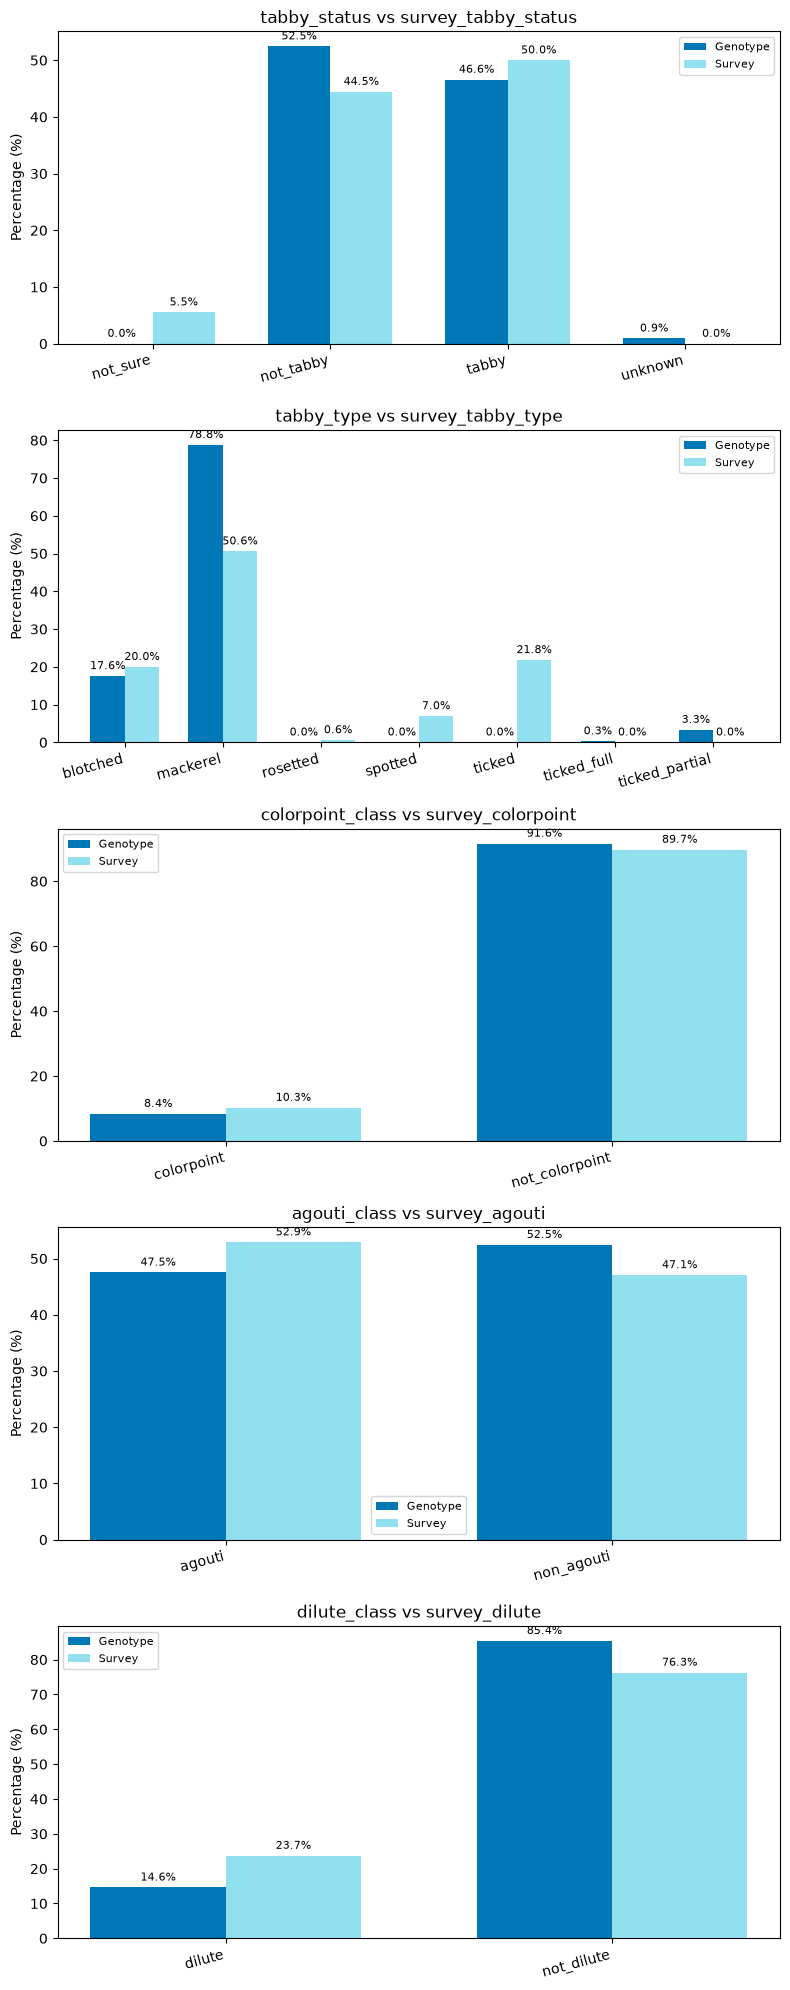

In [85]:
blue_colors = ['#0077b6', '#90e0ef']
def plot_geno_vs_survey_bar(df, pred_col, survey_col, ax, colors=blue_colors):
    non_missing = df[df[pred_col].notna() & df[survey_col].notna()]
    
    geno_counts = non_missing[pred_col].value_counts()
    survey_counts = non_missing[survey_col].value_counts()
    
    categories = sorted(set(geno_counts.index) | set(survey_counts.index))
    
    geno_pct = [geno_counts.get(cat, 0) / geno_counts.sum() * 100 for cat in categories]
    survey_pct = [survey_counts.get(cat, 0) / survey_counts.sum() * 100 for cat in categories]
    
    x = range(len(categories))
    width = 0.35
    
    bars1 = ax.bar([i - width/2 for i in x], geno_pct, width, label='Genotype', color=colors[0])
    bars2 = ax.bar([i + width/2 for i in x], survey_pct, width, label='Survey', color=colors[1])
    
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'{pred_col} vs {survey_col}')
    ax.set_xticks(list(x))
    ax.set_xticklabels(categories, rotation=15, ha='right')
    ax.legend(fontsize=8)
    
    for bars in (bars1, bars2):
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height:.1f}%',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)


# Plot all five traits, one per row
fig, axes = plt.subplots(5, 1, figsize=(8, 20))

trait_pairs = [
    ('tabby_status', 'survey_tabby_status'),
    ('tabby_type', 'survey_tabby_type'),
    ('colorpoint_class', 'survey_colorpoint'),
    ('agouti_class', 'survey_agouti'),
    ('dilute_class', 'survey_dilute'),
]
warnings.filterwarnings('ignore')
for ax, (pred_col, survey_col) in zip(axes, trait_pairs):
    plot_geno_vs_survey_bar(df_phenotype, pred_col, survey_col, ax)

plt.tight_layout()
plt.show()

In [86]:
def calc_metrics(pred, survey, positive_label):
    pred_pos = pred == positive_label
    survey_pos = survey == positive_label

    tp = (pred_pos & survey_pos).sum()
    fn = (~pred_pos & survey_pos).sum()
    tn = (~pred_pos & ~survey_pos).sum()
    fp = (pred_pos & ~survey_pos).sum()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    ppv = tp / (tp + fp) if (tp + fp) > 0 else float('nan')
    npv = tn / (tn + fn) if (tn + fn) > 0 else float('nan')

    return sensitivity, specificity, ppv, npv, tp, fn, tn, fp

In [87]:
for pred_col, survey_col in [
    ('colorpoint_class', 'survey_colorpoint'),
    ('agouti_class', 'survey_agouti'),
    ('dilute_class', 'survey_dilute'),
]:
    print(f"\n--- {pred_col} vs {survey_col} ---")
    
    missing_n = df_phenotype[survey_col].isna().sum()
    total_n = len(df_phenotype)
    print(f"Missing: {missing_n}/{total_n} ({missing_n/total_n:.1%})")
    
    non_missing = df_phenotype[df_phenotype[pred_col].notna() & df_phenotype[survey_col].notna()]
    print(pd.crosstab(non_missing[pred_col], non_missing[survey_col]))
    
    discordant = non_missing[pred_col] != non_missing[survey_col]
    n_compared = len(non_missing)
    print(f"Discordance: {discordant.sum()}/{n_compared} ({discordant.mean():.1%})")

        # Calculate performance metrics
    positive_label = 'colorpoint' if pred_col == 'colorpoint_class' else \
                     'agouti' if pred_col == 'agouti_class' else \
                     'dilute'

    sensitivity, specificity, ppv, npv, tp, fn, tn, fp = calc_metrics(
        non_missing[pred_col],
        non_missing[survey_col],
        positive_label
    )

    print(f"Sensitivity: {sensitivity:.3f}")
    print(f"Specificity: {specificity:.3f}")
    print(f"PPV:         {ppv:.3f}")
    print(f"NPV:         {npv:.3f}")


--- colorpoint_class vs survey_colorpoint ---
Missing: 333/1463 (22.8%)
survey_colorpoint  colorpoint  not_colorpoint
colorpoint_class                             
colorpoint                 83              11
not_colorpoint             32             995
Discordance: 43/1121 (3.8%)
Sensitivity: 0.722
Specificity: 0.989
PPV:         0.883
NPV:         0.969

--- agouti_class vs survey_agouti ---
Missing: 356/1463 (24.3%)
survey_agouti  agouti  non_agouti
agouti_class                     
agouti            453          68
non_agouti        127         448
Discordance: 195/1096 (17.8%)
Sensitivity: 0.781
Specificity: 0.868
PPV:         0.869
NPV:         0.779

--- dilute_class vs survey_dilute ---
Missing: 926/1463 (63.3%)
survey_dilute  dilute  not_dilute
dilute_class                     
dilute             64          13
not_dilute         61         389
Discordance: 74/527 (14.0%)
Sensitivity: 0.512
Specificity: 0.968
PPV:         0.831
NPV:         0.864


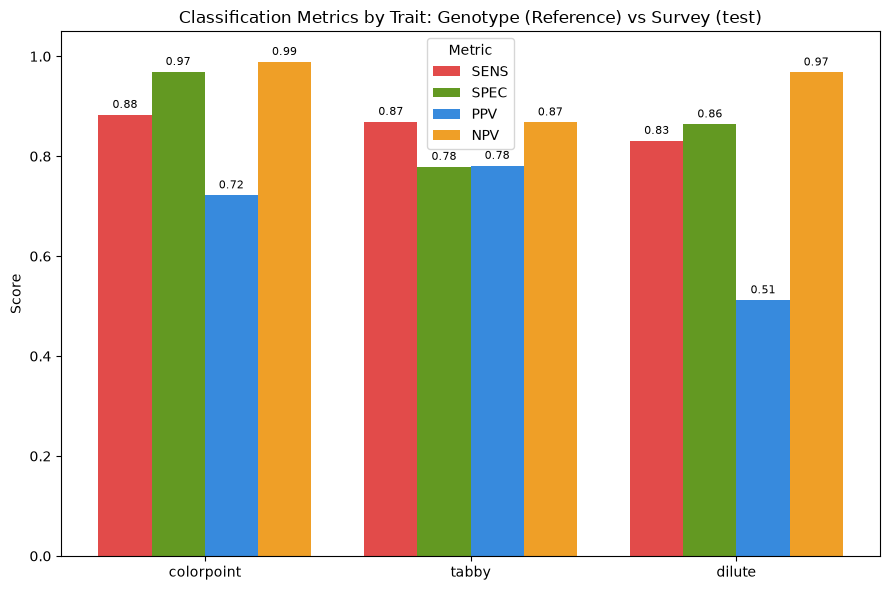

In [89]:
import matplotlib.pyplot as plt
import numpy as np

metrics_data = {
    'colorpoint': {'sens': 0.883, 'spec': 0.969, 'ppv': 0.722, 'npv': 0.989},
    'tabby':      {'sens': 0.869, 'spec': 0.779, 'ppv': 0.781, 'npv': 0.868},
    'dilute':     {'sens': 0.831, 'spec': 0.864, 'ppv': 0.512, 'npv': 0.968},
}

traits = list(metrics_data.keys())
metric_names = ['sens', 'spec', 'ppv', 'npv']
colors = ['#E24B4A', '#639922', '#378ADD', '#EF9F27']

x = np.arange(len(traits))
width = 0.2

fig, ax = plt.subplots(figsize=(9, 6))

for i, metric in enumerate(metric_names):
    values = [metrics_data[trait][metric] for trait in traits]
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, values, width, label=metric.upper(), color=colors[i])
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Classification Metrics by Trait: Genotype (Reference) vs Survey (test)')
ax.set_xticks(x)
ax.set_xticklabels(traits)
ax.legend(title='Metric')

plt.tight_layout()
plt.show()

Cats with a non-agouti genotype were excluded from the tabby-type comparison because they are expected to be solid. Orange is epistatic to agouti, but no solid red or apricot cats in this dataset had a non-agouti genotype together with an owner-reported tabby type. Ten non-agouti tortoiseshell cats with a Taqpep genotype and a reported tabby type were excluded; their pattern would show only in the orange patches. All 10 had a mackerel genotype, and owners reported 6 mackerel, 3 ticked, and 1 blotched.

In [90]:
print(f"\n--- tabby_type vs survey_tabby_type ---")

total_n = len(df_phenotype)

# Report each missingness pattern separately, rather than filtering on survey alone
geno_missing = df_phenotype['tabby_type'].isna()
survey_missing = df_phenotype['survey_tabby_type'].isna()
both_present = ~geno_missing & ~survey_missing

print(f"Survey missing: {survey_missing.sum()}/{total_n} ({survey_missing.mean():.1%})")
print(f"Genotype missing: {geno_missing.sum()}/{total_n} ({geno_missing.mean():.1%})")
print(f"Both present (comparable): {both_present.sum()}/{total_n} ({both_present.mean():.1%})")

# Only compare cats where BOTH values exist
comparable = df_phenotype[both_present].copy()
n_comparable = len(comparable)

# Normalize genotype labels so ticked subtypes match survey's single 'ticked' category
pred_normalized = comparable['tabby_type'].replace({'ticked_full': 'ticked', 'ticked_partial': 'ticked'})
survey_vals_col = comparable['survey_tabby_type']

# Identify survey categories genotype was never trying to predict
unmodeled = survey_vals_col.isin(['rosetted', 'spotted'])
print(f"Survey reports rosetted/spotted (not modeled by genotype): {unmodeled.sum()}/{n_comparable} ({unmodeled.mean():.1%})")

# --- Crosstab and discordance: exclude unmodeled rows ---
pred_modeled = pred_normalized[~unmodeled]
survey_modeled = survey_vals_col[~unmodeled]
n_modeled = len(pred_modeled)

print(pd.crosstab(pred_modeled, survey_modeled))

discordant = pred_modeled != survey_modeled
print(f"Discordance (excl. rosetted/spotted): {discordant.sum()}/{n_modeled} ({discordant.mean():.1%})")

# --- Per-category sensitivity/specificity/ppv/npv ---
# genotype (pred_normalized) as ground truth, survey as test -> pred first, survey second
labels = sorted(set(pred_modeled.unique()) | set(survey_modeled.unique()))

print("\nPer-category metrics (genotype = ground truth, survey = test):")
for label in labels:
    sens, spec, ppv, npv, tp, fn, tn, fp = calc_metrics(
        pred_modeled, survey_modeled, label
    )
    print(f"  {label:16s} sens={sens:.3f}  spec={spec:.3f}  ppv={ppv:.3f}  npv={npv:.3f}  "
          f"(tp={tp}, fn={fn}, tn={tn}, fp={fp})")


--- tabby_type vs survey_tabby_type ---
Survey missing: 989/1463 (67.6%)
Genotype missing: 876/1463 (59.9%)
Both present (comparable): 330/1463 (22.6%)
Survey reports rosetted/spotted (not modeled by genotype): 25/330 (7.6%)
survey_tabby_type  blotched  mackerel  ticked
tabby_type                                   
blotched                 41         5      10
mackerel                 24       162      51
ticked                    1         0      11
Discordance (excl. rosetted/spotted): 91/305 (29.8%)

Per-category metrics (genotype = ground truth, survey = test):
  blotched         sens=0.621  spec=0.937  ppv=0.732  npv=0.900  (tp=41, fn=25, tn=224, fp=15)
  mackerel         sens=0.970  spec=0.457  ppv=0.684  npv=0.926  (tp=162, fn=5, tn=63, fp=75)
  ticked           sens=0.153  spec=0.996  ppv=0.917  npv=0.792  (tp=11, fn=61, tn=232, fp=1)


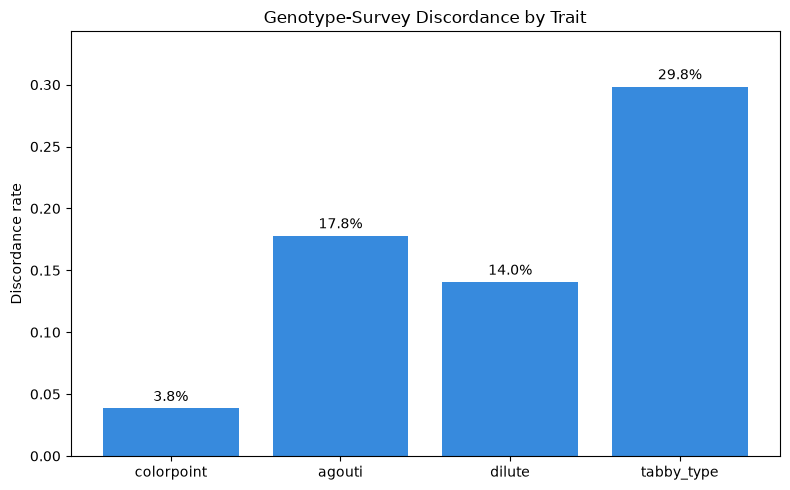

In [91]:
discordance_data = {
    'colorpoint': 43/1121,
    'agouti': 195/1096,
    'dilute': 74/527,
    'tabby_status': None,  # fill in from your Block 2 output
    'tabby_type': 91/305,
}

# Drop any traits you haven't filled in yet
discordance_data = {k: v for k, v in discordance_data.items() if v is not None}

traits = list(discordance_data.keys())
values = [discordance_data[t] for t in traits]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(traits, values, color='#378ADD')

for bar, val in zip(bars, values):
    ax.annotate(f'{val:.1%}',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Discordance rate')
ax.set_ylim(0, max(values) * 1.15)
ax.set_title('Genotype-Survey Discordance by Trait')
plt.tight_layout()
plt.show()

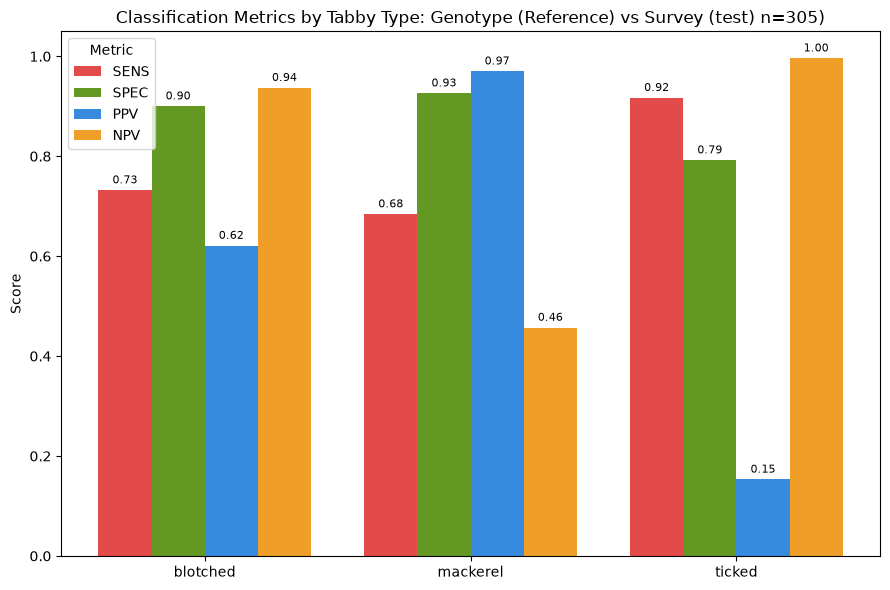

In [92]:
import matplotlib.pyplot as plt
import numpy as np

metrics_data = {
    'blotched': {'sens': 0.732, 'spec': 0.900, 'ppv': 0.621, 'npv': 0.937},
    'mackerel': {'sens': 0.684, 'spec': 0.926, 'ppv': 0.970, 'npv': 0.457},
    'ticked':   {'sens': 0.917, 'spec': 0.792, 'ppv': 0.153, 'npv': 0.996},
}

traits = list(metrics_data.keys())
metric_names = ['sens', 'spec', 'ppv', 'npv']
colors = ['#E24B4A', '#639922', '#378ADD', '#EF9F27']  # red, green, blue, yellow
x = np.arange(len(traits))
width = 0.2
fig, ax = plt.subplots(figsize=(9, 6))
for i, metric in enumerate(metric_names):
    values = [metrics_data[trait][metric] for trait in traits]
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, values, width, label=metric.upper(), color=colors[i])
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Classification Metrics by Tabby Type: Genotype (Reference) vs Survey (test) n=305)')
ax.set_xticks(x)
ax.set_xticklabels(traits)
ax.legend(title='Metric')
plt.tight_layout()
plt.show()

In [93]:
def build_geno_terms(row):
    terms = set()
    if pd.notna(row['dilute_class']):
        terms.add(('dilute', row['dilute_class']))
    if pd.notna(row['agouti_class']):
        label = 'tabby' if row['agouti_class'] == 'agouti' else 'not_tabby'
        terms.add(('pattern_presence', label))
    if pd.notna(row['tabby_type']):
        terms.add(('pattern_type', row['tabby_type']))          # mackerel/blotched/ticked
    if pd.notna(row['colorpoint_class']):
        terms.add(('colorpoint', row['colorpoint_class']))
    return frozenset(terms)

def build_survey_terms(row):
    # mirror structure exactly, pulling from survey_* columns
    terms = set()
    if pd.notna(row['survey_dilute']):
        terms.add(('dilute', row['survey_dilute']))
    if pd.notna(row['survey_tabby_status']):
        terms.add(('pattern_presence', row['survey_tabby_status']))
    if pd.notna(row['survey_tabby_type']):
        terms.add(('pattern_type', row['survey_tabby_type']))
    if pd.notna(row['survey_colorpoint']):
        terms.add(('colorpoint', row['survey_colorpoint']))
    return frozenset(terms)

df_phenotype['geno_terms'] = df_phenotype.apply(build_geno_terms, axis=1)
df_phenotype['survey_terms'] = df_phenotype.apply(build_survey_terms, axis=1)

In [94]:
def category_mismatches(row):
    geno_dict = dict(row['geno_terms'])
    survey_dict = dict(row['survey_terms'])
    shared_categories = set(geno_dict) & set(survey_dict)
    mismatched = [c for c in shared_categories if geno_dict[c] != survey_dict[c]]
    return pd.Series({
        'n_shared_categories': len(shared_categories),
        'n_mismatched': len(mismatched),
        'mismatched_categories': mismatched
    })

def add_mismatch_columns(df):
    cols = ['n_shared_categories', 'n_mismatched', 'mismatched_categories', 'mismatch_rate']
    df = df.drop(columns=[c for c in cols if c in df.columns])  # clear any/all prior versions first
    mismatch_info = df.apply(category_mismatches, axis=1)
    df = pd.concat([df, mismatch_info], axis=1)
    df['mismatch_rate'] = df['n_mismatched'] / df['n_shared_categories']
    return df

df_phenotype = add_mismatch_columns(df_phenotype)

In [95]:
df_phenotype['is_longhair'] = df_phenotype['1'].isin(['Longhair', 'Semi-longhair'])
df_phenotype['is_orange'] = df_phenotype['survey_orange'] == 'orange'
df_phenotype['is_dilute'] = df_phenotype['dilute_class'] == 'dilute'

df_phenotype['n_risk_factors'] = (
    df_phenotype['is_longhair'].astype(int) +
    df_phenotype['is_orange'].astype(int) +
    df_phenotype['is_dilute'].astype(int)
)

# Count cats with at least 2 of the 3
at_least_2 = (df_phenotype['n_risk_factors'] >= 2).sum()
print(at_least_2)

# See the full breakdown (0, 1, 2, or 3 risk factors)
print(df_phenotype['n_risk_factors'].value_counts().sort_index())

137
n_risk_factors
0    768
1    558
2    127
3     10
Name: count, dtype: int64


In [108]:
# Normalize genotype labels the same way previously
tabby_type_normalized = df_phenotype['tabby_type'].replace(
    {'ticked_full': 'ticked', 'ticked_partial': 'ticked'}
)

both_present = df_phenotype['tabby_type'].notna() & df_phenotype['survey_tabby_type'].notna()
unmodeled = df_phenotype['survey_tabby_type'].isin(['rosetted', 'spotted'])

df_phenotype['discordant_type'] = np.where(
    both_present & ~unmodeled,
    tabby_type_normalized != df_phenotype['survey_tabby_type'],
    np.nan  # can't determine concordance if either is missing, or survey reports an unmodeled category
)

df_phenotype.groupby('n_risk_factors')['discordant_type'].agg(['mean', 'count'])

,mean,count
n_risk_factors,,
0,0.146853,143
1,0.410072,139
2,0.545455,22
3,1.000000,1


The following code block assigns cats to one of 16 categories, which I talked about in my presentation.

In [97]:
def assign_bucket(row):
    dilute = row['dilute_class']
    colorpoint = row['colorpoint_class']
    agouti = row['agouti_class']
    
    # Require all core traits to be non-null before assigning any bucket
    if pd.isna(dilute) or pd.isna(colorpoint) or pd.isna(agouti):
        return None
    
    if agouti == 'non_agouti':
        return f"{dilute}_{colorpoint}_solid"
    else:
        pattern = row['tabby_type']
        if pd.isna(pattern):
            return None
        if pattern in ('ticked_full', 'ticked_partial'):
            pattern = 'ticked'
        # Only keep the 3 patterns you're modeling; anything else (rosetted/spotted) is unbucketed
        if pattern not in ('mackerel', 'blotched', 'ticked'):
            return None
        return f"{dilute}_{colorpoint}_{pattern}"

df_phenotype['bucket'] = df_phenotype.apply(assign_bucket, axis=1)

bucket_counts = df_phenotype['bucket'].value_counts(dropna=True)
n_unbucketed = df_phenotype['bucket'].isna().sum()

print(bucket_counts)
print(f"\nTotal buckets populated: {bucket_counts.shape[0]} / 16 possible")
print(f"Cats excluded (missing genotype data): {n_unbucketed}/{len(df_phenotype)} ({n_unbucketed/len(df_phenotype):.1%})")

bucket
not_dilute_not_colorpoint_solid       536
not_dilute_not_colorpoint_mackerel    322
dilute_not_colorpoint_solid           150
dilute_not_colorpoint_mackerel         83
not_dilute_not_colorpoint_blotched     81
not_dilute_colorpoint_solid            49
dilute_colorpoint_solid                25
not_dilute_not_colorpoint_ticked       23
not_dilute_colorpoint_mackerel         23
dilute_not_colorpoint_blotched         17
not_dilute_colorpoint_blotched          6
dilute_colorpoint_mackerel              6
dilute_colorpoint_blotched              4
dilute_not_colorpoint_ticked            3
Name: count, dtype: int64

Total buckets populated: 14 / 16 possible
Cats excluded (missing genotype data): 135/1463 (9.2%)


In [109]:
from scipy.stats import fisher_exact

# Define the target group: owners who called their cat 'ticked'
ticked_survey_idx_72 = comparable[comparable['survey_tabby_type'] == 'ticked'].index
print(len(ticked_survey_idx_72))  # should be 72

def test_enrichment(df, target_idx, col):
    is_target = df.index.isin(target_idx)
    target_vals = df.loc[is_target, col].dropna()
    background_vals = df.loc[~is_target, col].dropna()

    a = target_vals.sum()                    # positive in target group
    b = len(target_vals) - a                 # negative in target group
    c = background_vals.sum()                # positive in background
    d = len(background_vals) - c             # negative in background

    table = [[a, b], [c, d]]
    odds_ratio, p = fisher_exact(table)

    print(f"{col}:")
    print(f"  Target:     {a}/{len(target_vals)} ({a/len(target_vals):.1%})")
    print(f"  Background: {c}/{len(background_vals)} ({c/len(background_vals):.1%})")
    print(f"  OR={odds_ratio:.3f}, Fisher exact p={p:.4f}\n")
    return table, odds_ratio, p


72


In [99]:
df_phenotype['is_longhair_na'] = np.where(df_phenotype['1'].isna(), np.nan,
                                          df_phenotype['1'].isin(['Longhair','Semi-longhair']))
df_phenotype['is_dilute_na']   = np.where(df_phenotype['dilute_class'].isna(), np.nan,
                                          df_phenotype['dilute_class'] == 'dilute')
df_phenotype['is_orange_na']   = np.where(df_phenotype['survey_orange'].isna(), np.nan,
                                          df_phenotype['survey_orange'] == 'orange')

In [100]:
for col in ['is_dilute_na', 'is_orange_na', 'is_longhair_na']:
    test_enrichment(df_phenotype, ticked_survey_idx_72, col)

is_dilute_na:
  Target:     14.0/72 (19.4%)
  Background: 292.0/1365 (21.4%)
  OR=0.887, Fisher exact p=0.7692

is_orange_na:
  Target:     15.0/27 (55.6%)
  Background: 109.0/425 (25.6%)
  OR=3.624, Fisher exact p=0.0015

is_longhair_na:
  Target:     42.0/72 (58.3%)
  Background: 370.0/1124 (32.9%)
  OR=2.853, Fisher exact p=0.0000



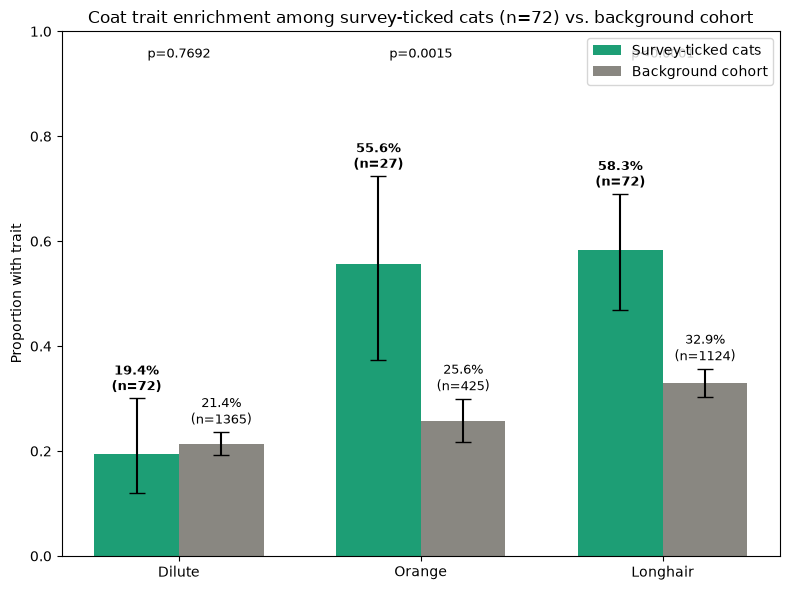

In [101]:
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.stats.proportion import proportion_confint

# Counts: (target_positive, target_n, background_positive, background_n, p_value)
data = {
    'Dilute':   (14, 72, 292, 1365, 0.7692),
    'Orange':   (15, 27, 109, 425, 0.0015),
    'Longhair': (42, 72, 370, 1124, 0.0000),
}

traits = list(data.keys())
x = np.arange(len(traits))
width = 0.35

target_props, target_err = [], []
bg_props, bg_err = [], []

for trait in traits:
    tp, tn, bp, bn, _ = data[trait]

    p_t = tp / tn
    ci_t = proportion_confint(tp, tn, method='wilson')
    target_props.append(p_t)
    target_err.append([p_t - ci_t[0], ci_t[1] - p_t])

    p_b = bp / bn
    ci_b = proportion_confint(bp, bn, method='wilson')
    bg_props.append(p_b)
    bg_err.append([p_b - ci_b[0], ci_b[1] - p_b])

target_err = np.array(target_err).T
bg_err = np.array(bg_err).T

fig, ax = plt.subplots(figsize=(8, 6))

bars_target = ax.bar(x - width/2, target_props, width, yerr=target_err, capsize=6,
                      color='#1D9E75', label='Survey-ticked cats')
bars_bg = ax.bar(x + width/2, bg_props, width, yerr=bg_err, capsize=6,
                  color='#898781', label='Background cohort')

for i, trait in enumerate(traits):
    tp, tn, bp, bn, p = data[trait]
    ax.annotate(f'{target_props[i]:.1%}\n(n={tn})',
                xy=(x[i] - width/2, target_props[i] + target_err[1][i]),
                xytext=(0, 6), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
    ax.annotate(f'{bg_props[i]:.1%}\n(n={bn})',
                xy=(x[i] + width/2, bg_props[i] + bg_err[1][i]),
                xytext=(0, 6), textcoords='offset points', ha='center', fontsize=9)
    sig_label = f'p={p:.4f}' if p >= 0.0001 else 'p<0.0001'
    ax.text(x[i], 0.95, sig_label, ha='center', fontsize=9,
            transform=ax.get_xaxis_transform())

ax.set_ylabel('Proportion with trait')
ax.set_ylim(0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels(traits)
ax.set_title('Coat trait enrichment among survey-ticked cats (n=72) vs. background cohort')
ax.legend()
plt.tight_layout()
plt.savefig('ticked_enrichment.png', dpi=150)
plt.show()

In [102]:
# Restrict to the same 330 cats used in the tabby-type comparison
both_present = df_phenotype['tabby_type'].notna() & df_phenotype['survey_tabby_type'].notna()
comparable = df_phenotype[both_present].copy()

# NaN-aware dilute predictor — don't silently code missing dilute_class as "not dilute"
comparable['is_dilute'] = np.where(comparable['dilute_class'].isna(), np.nan,
                                    comparable['dilute_class'] == 'dilute')

print(f"n = {len(comparable)}")
print(f"is_dilute missing: {comparable['is_dilute'].isna().sum()}")

# Simple bivariate test: is dilute status associated with tabby-type discordance?
ct = pd.crosstab(comparable['is_dilute'], comparable['discordant_type'])
print(ct)

from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(ct)
print(f"chi2={chi2:.3f}, p={p:.4f}")
comparable['is_longhair'] = np.where(comparable['1'].isna(), np.nan,
                                      comparable['1'].isin(['Longhair', 'Semi-longhair']))

print(f"is_longhair missing: {comparable['is_longhair'].isna().sum()}")

ct_lh = pd.crosstab(comparable['is_longhair'], comparable['discordant_type'])
print(ct_lh)

chi2, p, dof, expected = chi2_contingency(ct_lh)
print(f"chi2={chi2:.3f}, p={p:.4f}")

n = 330
is_dilute missing: 4
discordant_type  0.0  1.0
is_dilute                
0.0              182   70
1.0               28   21
chi2=3.736, p=0.0532
is_longhair missing: 0
discordant_type  0.0  1.0
is_longhair              
0.0              167   45
1.0               47   46
chi2=23.289, p=0.0000


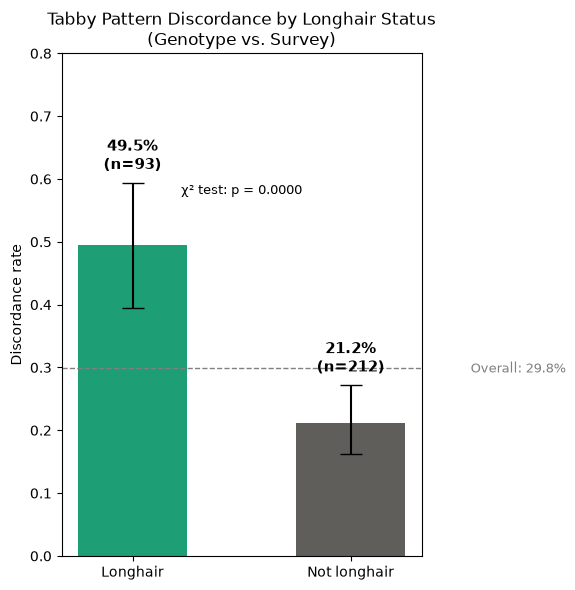

In [103]:
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

# Pull counts from the crosstab you already built
n_lh = ct_lh.loc[1.0].sum()
x_lh = ct_lh.loc[1.0, 1.0]
n_not = ct_lh.loc[0.0].sum()
x_not = ct_lh.loc[0.0, 1.0]

p_lh = x_lh / n_lh
p_not = x_not / n_not
overall = comparable['discordant_type'].mean()

ci_lh = proportion_confint(x_lh, n_lh, method='wilson')
ci_not = proportion_confint(x_not, n_not, method='wilson')

fig, ax = plt.subplots(figsize=(6, 6))

categories = ['Longhair', 'Not longhair']
values = [p_lh, p_not]
errors = [
    [p_lh - ci_lh[0], p_not - ci_not[0]],
    [ci_lh[1] - p_lh, ci_not[1] - p_not]
]
ns = [n_lh, n_not]
colors = ['#1D9E75', '#5F5E5A']

bars = ax.bar(categories, values, yerr=errors, capsize=8, color=colors, width=0.5)

for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.annotate(f'{height:.1%}\n(n={ns[i]})',
                xy=(bar.get_x() + bar.get_width() / 2, height + errors[1][i]),
                xytext=(0, 6), textcoords='offset points',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.axhline(overall, color='gray', linestyle='--', linewidth=1)
ax.text(1.55, overall, f'Overall: {overall:.1%}', va='center', fontsize=9, color='gray')

ax.set_ylabel('Discordance rate')
ax.set_ylim(0, 0.8)
ax.set_title('Tabby Pattern Discordance by Longhair Status\n(Genotype vs. Survey)')
chi2, p, dof, expected = chi2_contingency(ct_lh)
ax.text(0.5, 0.72, f'\u03c7\u00b2 test: p = {p:.4f}', ha='center', transform=ax.transAxes, fontsize=9)

plt.tight_layout()
plt.savefig('longhair_discordance.png', dpi=150)
plt.show()

In [107]:
tabby_type_norm = df_phenotype['tabby_type'].replace(
    {'ticked_full': 'ticked', 'ticked_partial': 'ticked'})

unmodeled = df_phenotype['survey_tabby_type'].isin(['spotted', 'rosetted'])
both_present = (df_phenotype['tabby_type'].notna() &
                df_phenotype['survey_tabby_type'].notna() &
                ~unmodeled)

df_phenotype['discordant_type'] = np.where(
    both_present,
    tabby_type_norm != df_phenotype['survey_tabby_type'],
    np.nan
)

In [105]:
import statsmodels.formula.api as smf
import numpy as np
comparable['discordant_type'] = df_phenotype.loc[comparable.index, 'discordant_type']
comparable['is_dilute'] = np.where(comparable['dilute_class'].isna(), np.nan,
                                    comparable['dilute_class'] == 'dilute')
comparable['is_longhair'] = np.where(comparable['1'].isna(), np.nan,
                                      comparable['1'].isin(['Longhair', 'Semi-longhair']))
model_no_orange = smf.logit('discordant_type ~ is_dilute + is_longhair', data=comparable).fit()
print(model_no_orange.summary())
print(f"n used: {int(model_no_orange.nobs)}")

Optimization terminated successfully.
         Current function value: 0.562079
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:        discordant_type   No. Observations:                  301
Model:                          Logit   Df Residuals:                      298
Method:                           MLE   Df Model:                            2
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.08280
Time:                        19:24:39   Log-Likelihood:                -169.19
converged:                       True   LL-Null:                       -184.46
Covariance Type:            nonrobust   LLR p-value:                 2.327e-07
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -1.5132      0.195     -7.761      0.000      -1.895      -1.131
is_dilute       0.9681    

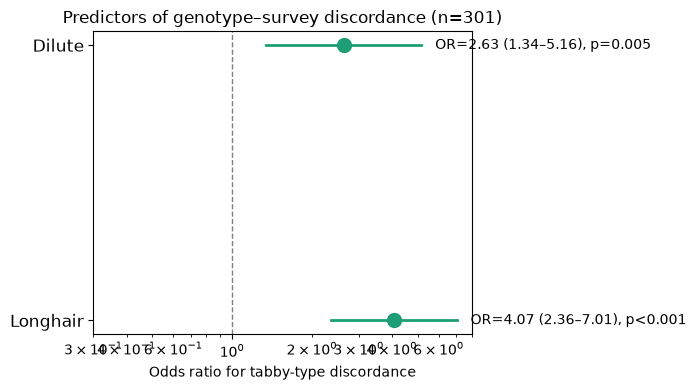

In [106]:
import matplotlib.pyplot as plt
import numpy as np

# Pull odds ratios and CIs directly from the fitted model (no hardcoding)
params = model_no_orange.params.drop('Intercept')
conf = model_no_orange.conf_int().drop('Intercept')
pvals = model_no_orange.pvalues.drop('Intercept')

or_vals = np.exp(params)
ci_low = np.exp(conf[0])
ci_high = np.exp(conf[1])

labels = ['Dilute', 'Longhair']  # matches params.index order: is_dilute, is_longhair
y_pos = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(7, 4))

colors = ['#898781' if p >= 0.05 else '#1D9E75' for p in pvals]

for i, label in enumerate(labels):
    ax.plot([ci_low.iloc[i], ci_high.iloc[i]], [y_pos[i], y_pos[i]],
             color=colors[i], linewidth=2)
    ax.plot(or_vals.iloc[i], y_pos[i], 'o', color=colors[i], markersize=10)
    sig = f'p={pvals.iloc[i]:.3f}' if pvals.iloc[i] >= 0.001 else 'p<0.001'
    ax.annotate(f'OR={or_vals.iloc[i]:.2f} ({ci_low.iloc[i]:.2f}\u2013{ci_high.iloc[i]:.2f}), {sig}',
                xy=(ci_high.iloc[i], y_pos[i]), xytext=(10, 0),
                textcoords='offset points', va='center', fontsize=10)

ax.axvline(1, color='gray', linestyle='--', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=12)
ax.set_xlabel('Odds ratio for tabby-type discordance')
ax.set_xscale('log')
ax.set_xlim(0.3, 8)
ax.set_title(f'Predictors of genotype\u2013survey discordance (n={int(model_no_orange.nobs)})')
ax.invert_yaxis()  # longhair on top, matches params order if you want dilute first instead, just flip labels

plt.tight_layout()
plt.savefig('discordance_forest_plot.png', dpi=150)
plt.show()